# EDA: the ratings table

One row is one entry of a user's list: an anime, a status, an optional score, a progress
count and the time of the last edit.

Inputs: `data/clean/cleaning_report.json`, the committed tables in `tables/`
(`status_score.csv`, `progress.csv`, `anime_stats.parquet`) and the local 1% user sample
`data/eda/sample_ratings.parquet`.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import config, plotting
from cleaning.plotting import BLUE, MUTED

plotting.use_style()
pl.Config.set_tbl_rows(30)

report = json.loads(config.CLEAN_REPORT.read_text())
status_score = pl.read_csv(config.TABLES / "status_score.csv")
progress = pl.read_csv(config.TABLES / "progress.csv")
anime_stats = pl.read_parquet(config.TABLES / "anime_stats.parquet")
sample = pl.read_parquet(config.SAMPLE_RATINGS)

rows = status_score["n"].sum()
n_users = report["users"]["accounts_kept"]
n_anime = anime_stats.height
print(f"{rows:,} rows = {n_users:,} users x {n_anime:,} anime with at least one row")
print(f"density {rows / (n_users * n_anime):.3%} (sparsity {1 - rows / (n_users * n_anime):.3%}), "
      f"{rows / n_users:.0f} rows per user on average")
print("cleaning removed:", {k: v for k, v in report["ratings"].items() if k.startswith("dropped_")})

548,928,922 rows = 1,907,258 users x 30,408 anime with at least one row
density 0.946% (sparsity 99.054%), 288 rows per user on average
cleaning removed: {'dropped_no_status': 226323, 'dropped_unknown_anime': 400, 'dropped_account_rows': 4621185, 'dropped_duplicate': 13}


## 1. Status

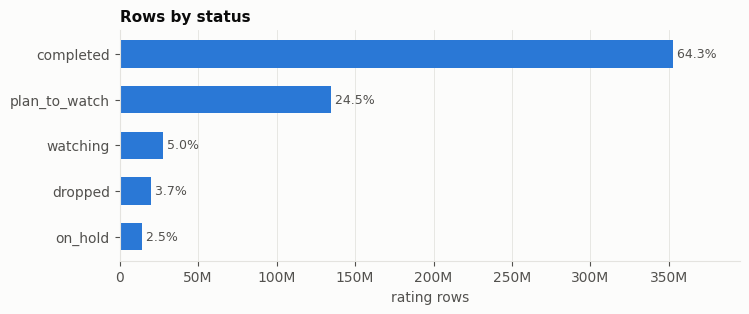

In [2]:
by_status = status_score.group_by("status").agg(pl.col("n").sum()).sort("n", descending=True)
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(by_status["status"].to_list(), by_status["n"].to_list(), color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f" {v / rows:.1%}" for v in by_status["n"]], color=MUTED, fontsize=9)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, by_status["n"].max() * 1.12)
plotting.thousands(ax, "x")
ax.set_xlabel("rating rows"); ax.set_title("Rows by status")
plt.show()

Two thirds of the rows (64%) are completed anime and a quarter (25%) are plan_to_watch.
Watching (5%), dropped (4%) and on hold (3%) are small. Read as feedback: completed and
watching are evidence of consumption, dropped is negative evidence, and plan_to_watch is
declared interest without consumption, a different signal from both.

## 2. Scores

Score 0 means the user did not score the entry.

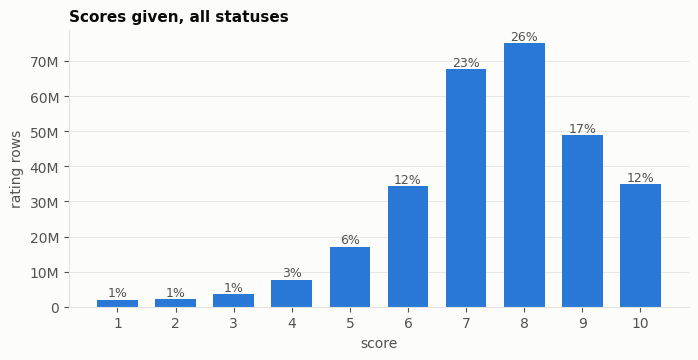

293,995,374 scored rows (53.6% of all rows), mean 7.51; scores 1-4: 5.3%, scores 7-10: 77.2%


In [3]:
scored = status_score.filter(pl.col("score") > 0)
overall = scored.group_by("score").agg(pl.col("n").sum()).sort("score")
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(overall["score"], overall["n"], color=BLUE, width=0.7)
ax.bar_label(bars, labels=[f"{v / overall['n'].sum():.0%}" for v in overall["n"]], color=MUTED, fontsize=9)
ax.set_xticks(range(1, 11)); ax.grid(axis="x", visible=False)
plotting.thousands(ax)
ax.set_xlabel("score"); ax.set_ylabel("rating rows"); ax.set_title("Scores given, all statuses")
plt.show()
mean = (overall["score"] * overall["n"]).sum() / overall["n"].sum()
print(f"{overall['n'].sum():,} scored rows ({overall['n'].sum() / rows:.1%} of all rows), mean {mean:.2f}; "
      f"scores 1-4: {overall.filter(pl.col('score') <= 4)['n'].sum() / overall['n'].sum():.1%}, "
      f"scores 7-10: {overall.filter(pl.col('score') >= 7)['n'].sum() / overall['n'].sum():.1%}")

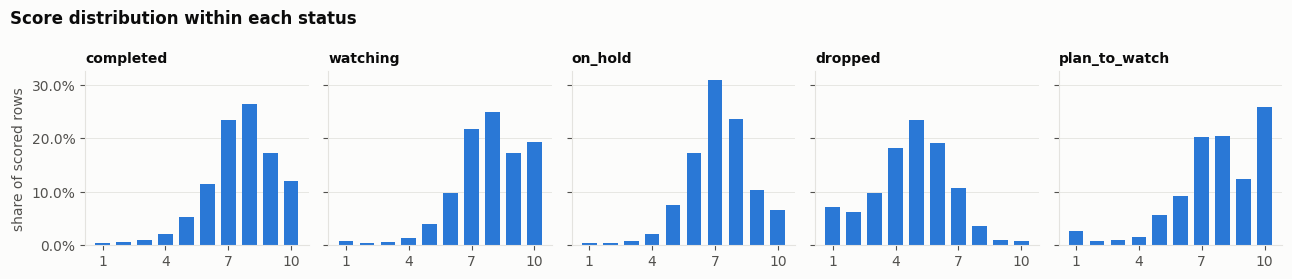

shape: (5, 4)
┌───────────────┬───────────┬──────────┬────────────┐
│ status        ┆ rows      ┆ unscored ┆ mean score │
│ ---           ┆ ---       ┆ ---      ┆ ---        │
│ str           ┆ i64       ┆ str      ┆ f64        │
╞═══════════════╪═══════════╪══════════╪════════════╡
│ completed     ┆ 352826954 ┆ 21.9%    ┆ 7.58       │
│ watching      ┆ 27362373  ┆ 78.1%    ┆ 7.86       │
│ on_hold       ┆ 13956617  ┆ 77.3%    ┆ 7.17       │
│ dropped       ┆ 20060580  ┆ 58.4%    ┆ 4.74       │
│ plan_to_watch ┆ 134722398 ┆ 99.3%    ┆ 7.73       │
└───────────────┴───────────┴──────────┴────────────┘


In [4]:
order = ["completed", "watching", "on_hold", "dropped", "plan_to_watch"]
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=True)
table = []
for ax, status in zip(axes, order):
    s = status_score.filter(pl.col("status") == status)
    total = s["n"].sum()
    with_score = s.filter(pl.col("score") > 0).sort("score")
    ax.bar(with_score["score"], with_score["n"] / with_score["n"].sum(), color=BLUE, width=0.7)
    ax.set_xticks([1, 4, 7, 10]); ax.grid(axis="x", visible=False)
    ax.set_title(status, fontsize=10)
    table.append({"status": status, "rows": total, "unscored": f"{1 - with_score['n'].sum() / total:.1%}",
                  "mean score": round((with_score["score"] * with_score["n"]).sum() / with_score["n"].sum(), 2)})
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel("share of scored rows")
fig.suptitle("Score distribution within each status", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
print(pl.DataFrame(table))

Scores are top-heavy: 77% of scored rows are 7 or higher and 5% are 4 or lower, with a mean of
7.5. Only 54% of rows carry a score at all, and 22% of completed anime are unscored. Dropped
anime are the exception: when scored they average 4.7. Status and score agree, then: low scores
mostly sit on dropped anime, and "completed without a score" should not be read as dislike.
The few scores on plan_to_watch rows (0.7% of them) are noise.

## 3. Progress: how far users get before they stop

`episodes_watched / episodes` for entries whose anime has a known episode count, in tenths.

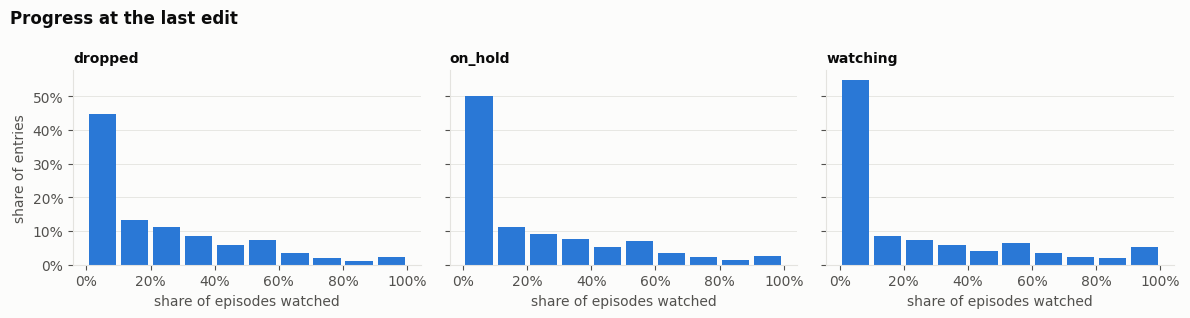

dropped  : 45% stop in the first tenth, 16% are past the halfway point
on_hold  : 50% stop in the first tenth, 17% are past the halfway point
watching : 55% stop in the first tenth, 19% are past the halfway point


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, status in zip(axes, ("dropped", "on_hold", "watching")):
    p = progress.filter(pl.col("status") == status).sort("decile")
    ax.bar(p["decile"] / 10 + 0.05, p["n"] / p["n"].sum(), width=0.085, color=BLUE)
    ax.set_title(status, fontsize=10); ax.set_xlabel("share of episodes watched")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel("share of entries")
fig.suptitle("Progress at the last edit", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
for status in ("dropped", "on_hold", "watching"):
    p = progress.filter(pl.col("status") == status).sort("decile")
    print(f"{status:9s}: {p['n'][0] / p['n'].sum():.0%} stop in the first tenth, "
          f"{p.filter(pl.col('decile') >= 5)['n'].sum() / p['n'].sum():.0%} are past the halfway point")

Users who drop an anime mostly do it early: 45% of dropped entries stop within the first tenth
of the episodes and only 16% are past halfway. On-hold entries look the same. Many `watching`
entries are stale: 55% are still in the first tenth, which includes entries with no episode
watched at all, so `watching` is weaker evidence of interest than `completed`.

## 4. Optional fields, from a 1% sample of users

In [6]:
n = sample.height
by = sample.group_by("status").agg(
    pl.len().alias("rows"),
    pl.col("updated_at").is_not_null().mean().alias("updated_at"),
    pl.col("start_date").is_not_null().mean().alias("start_date"),
    pl.col("finish_date").is_not_null().mean().alias("finish_date"),
    pl.col("is_rewatching").mean().alias("is_rewatching"),
    (pl.col("episodes_watched") > 0).mean().alias("episodes_watched > 0"),
).sort("rows", descending=True)
print(f"sample: {sample['user_id'].n_unique():,} users, {n:,} rows")
print(by.with_columns(pl.exclude("status", "rows").round(3)))
both = sample.filter(pl.col("start_date").is_not_null() & pl.col("finish_date").is_not_null() & (pl.col("status") == "completed"))
span = (both["finish_date"] - both["start_date"]).dt.total_days()
print(f"completed entries with both dates: {both.height / sample.filter(pl.col('status') == 'completed').height:.1%}; "
      f"finish before start in {(span < 0).mean():.2%}; same day in {(span == 0).mean():.1%}; median {span.median():.0f} days")

sample: 19,073 users, 5,488,773 rows
shape: (5, 7)
┌───────────────┬─────────┬────────────┬────────────┬─────────────┬───────────────┬────────────────┐
│ status        ┆ rows    ┆ updated_at ┆ start_date ┆ finish_date ┆ is_rewatching ┆ episodes_watch │
│ ---           ┆ ---     ┆ ---        ┆ ---        ┆ ---         ┆ ---           ┆ ed > 0         │
│ enum          ┆ u32     ┆ f64        ┆ f64        ┆ f64         ┆ f64           ┆ ---            │
│               ┆         ┆            ┆            ┆             ┆               ┆ f64            │
╞═══════════════╪═════════╪════════════╪════════════╪═════════════╪═══════════════╪════════════════╡
│ completed     ┆ 3498288 ┆ 1.0        ┆ 0.162      ┆ 0.309       ┆ 0.001         ┆ 0.995          │
│ plan_to_watch ┆ 1375706 ┆ 1.0        ┆ 0.011      ┆ 0.003       ┆ 0.0           ┆ 0.014          │
│ watching      ┆ 274475  ┆ 1.0        ┆ 0.301      ┆ 0.016       ┆ 0.0           ┆ 0.575          │
│ dropped       ┆ 195847  ┆ 1.0        ┆

`updated_at` is always present. The user-entered watch dates are not: 31% of completed entries
have a finish date, 16% a start date and 15% both, and when both exist a third are the same
day. They cannot replace `updated_at` as a time axis. `is_rewatching` marks a rewatch in
progress and is set on 0.1% of completed rows; it is not a count of rewatches.